# SMS spam classification: LSTM and BiLSTM

This project learns to distinguish **normal messages (ham)** from **spam**.
The core implementation lives in Python modules; this notebook walks through
sequence shapes, text encoding, controlled experiments, and evaluation.

The main command is `python -m text_classification.run_experiment`. The saved
analysis runs without the original corpus. Optional retraining uses an official
UCI download kept under Git-ignored `data/`; real message bodies, numbers, learned
vocabulary, and model weights are not published here.

**Dataset attribution:** Almeida, T. & Hidalgo, J. (2011).
[SMS Spam Collection](https://doi.org/10.24432/C5CC84), UCI Machine Learning
Repository, listed under [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).
See [source and license notices](../THIRD_PARTY_NOTICES.md) for the earlier
MathWorks example, the official-versus-local data distinction, and processing
changes. The module's own code uses MIT; it does not relicense the dataset.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display

from text_classification.data import build_vocabulary, encode_messages
from text_classification.models import SequenceModel, SpamClassifier
from text_classification.plotting import learning_curves, comparison, confusion_matrices, data_summary

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").is_file():
    ROOT = ROOT.parent
assert (ROOT / "text_classification").is_dir(), "Start in the repository or module directory."
RESULTS = ROOT / "text_classification" / "results"
torch.set_num_threads(1)


## 1. Understand the sequence dimensions

A sequence tensor has shape `(batch, time, features)`. The two small examples
below use generated values to show the layer dimensions; they are not trained
classifiers or regressors.

For classification, a 20-feature input passes through an LSTM with hidden size
30 and a dense layer with 10 outputs. There are 10 **logits per time step**, but
only one predicted class ID per time step. For regression, a 40-feature input
passes through an LSTM with hidden size 100 and a one-output dense layer.

`SequenceModel` implements these sequence-to-sequence examples. The actual SMS
classifier later produces one label for an entire variable-length message.

In [2]:
torch.manual_seed(42)
classifier = SequenceModel(input_size=20, hidden_size=30, output_size=10)
regressor = SequenceModel(input_size=40, hidden_size=100, output_size=1)
classification_input = torch.randn(2, 7, 20)
regression_input = torch.randn(2, 7, 40)
with torch.no_grad():
    class_logits = classifier(classification_input)
    probabilities = class_logits.softmax(dim=-1)
    class_ids = class_logits.argmax(dim=-1)
    numeric_outputs = regressor(regression_input)

display(pd.DataFrame([
    {"stage": "Classification input", "shape": tuple(classification_input.shape)},
    {"stage": "Class logits / probabilities", "shape": tuple(class_logits.shape)},
    {"stage": "Predicted class IDs", "shape": tuple(class_ids.shape)},
    {"stage": "Regression input", "shape": tuple(regression_input.shape)},
    {"stage": "Regression outputs", "shape": tuple(numeric_outputs.shape)},
]))
assert torch.allclose(probabilities.sum(dim=-1), torch.ones(2, 7), atol=1e-6)


,stage,shape
0,Classification input,"(2, 7, 20)"
1,Class logits / probabilities,"(2, 7, 10)"
2,Predicted class IDs,"(2, 7)"
3,Regression input,"(2, 7, 40)"
4,Regression outputs,"(2, 7, 1)"


## 2. Turn words into variable-length sequences

The example sentences below are invented for this notebook. The small displayed
vocabulary belongs only to these examples, not to the SMS corpus.

Words become integer IDs. ID 0 is padding; ID 1 is an unknown word. The learned
embedding maps each non-padding ID to a 50-dimensional vector. Real training
uses a vocabulary learned only from training messages, truncates at 60 tokens,
and handles empty normalized text with one unknown token.

Right-padding makes a rectangular batch, but padding is not actual text.
`pack_padded_sequence` lets the LSTM process the true lengths. BiLSTM concatenates
the final forward and backward states, giving 160 features when each direction
has 80 hidden units. Taking the last padded output would be incorrect.

In [3]:
invented_texts = ["Lumen project briefing moved to Tuesday.", "Lumen project update."]
toy_vocabulary = build_vocabulary(invented_texts)
toy_tokens, toy_lengths = encode_messages(invented_texts + ["Unseenword"], toy_vocabulary, max_length=8)
display(pd.DataFrame({"token": list(toy_vocabulary), "id": list(toy_vocabulary.values())}))
print("Invented-example token IDs:")
print(toy_tokens)
print("Valid lengths:", toy_lengths.tolist())

toy_model = SpamClassifier(len(toy_vocabulary), bidirectional=True, head_sizes=(30, 10)).eval()
with torch.no_grad():
    toy_logits = toy_model(toy_tokens, toy_lengths)
print("SMS model output shape:", tuple(toy_logits.shape), "— two logits per message.")
print("This shape demonstration uses an untrained model; its values are not predictions to interpret.")


,token,id
0,<pad>,0
1,<unk>,1
2,lumen,2
3,project,3
4,briefing,4
5,moved,5
6,to,6
7,tuesday,7
8,update,8


Invented-example token IDs:
tensor([[2, 3, 4, 5, 6, 7, 0, 0],
        [2, 3, 8, 0, 0, 0, 0, 0],
        [1, 0, 0, 0, 0, 0, 0, 0]])
Valid lengths: [6, 3, 1]
SMS model output shape: (3, 2) — two logits per message.
This shape demonstration uses an untrained model; its values are not predictions to interpret.


## 3. Read the recorded experiment or retrain locally

The default reads public aggregate results and needs no corpus download.
To retrain, first run `python -m text_classification.data --download` from the
repository root, then set `RETRAIN = True`. That calls the same main experiment
function used by the CLI and replaces the eight result files.

The UCI text file has 5,574 rows. The earlier local CSV had 5,572 rows and format
and content differences. This version deliberately uses the checksummed official
source with documented terms; it does not reuse or publish that CSV.

In [4]:
RETRAIN = False
if RETRAIN:
    from text_classification.run_experiment import run_experiment, save_results
    trained = run_experiment(epochs=5, threads=1)
    save_results(trained, RESULTS)

result = {name: pd.read_csv(RESULTS / f"{name}.csv") for name in ("metrics", "history", "confusion")}
result["metadata"] = json.loads((RESULTS / "metadata.json").read_text())
metadata = result["metadata"]
print(f"Source rows: {metadata['source_rows']}; normalized duplicates removed: {metadata['duplicates_removed']}.")
print(f"Unique normalized messages: {metadata['unique_messages']}.")
print(f"Recorded training: {metadata['epochs']} epochs per neural model; seed {metadata['seed']}; CPU.")


Source rows: 5574; normalized duplicates removed: 444.
Unique normalized messages: 5130.
Recorded training: 5 epochs per neural model; seed 42; CPU.


## 4. Split before fitting features

Lowercasing and word/number tokenization are fixed rules. Removing normalized
exact duplicates **before** splitting prevents identical normalized messages
from appearing in multiple splits. Conflicting labels for identical normalized
messages cause a validation error rather than an arbitrary choice.

The remaining messages are stratified 70/15/15. The neural vocabulary, TF-IDF
vocabulary/IDF, and classifiers are fit on training data only. Validation selects
checkpoints/configurations. Test labels are used only after those choices are
fixed. Related spam templates can still cross splits; this is not a sender-held-out
or chronological benchmark.

Notice the class imbalance. A model predicting only ham will look reasonably
accurate while failing to catch any spam.

,ham,spam,total
train,3149,441,3590
validation,676,94,770
test,676,94,770


Training-only neural vocabulary (including PAD/UNK): 7250
Training messages truncated above 60 tokens: 27


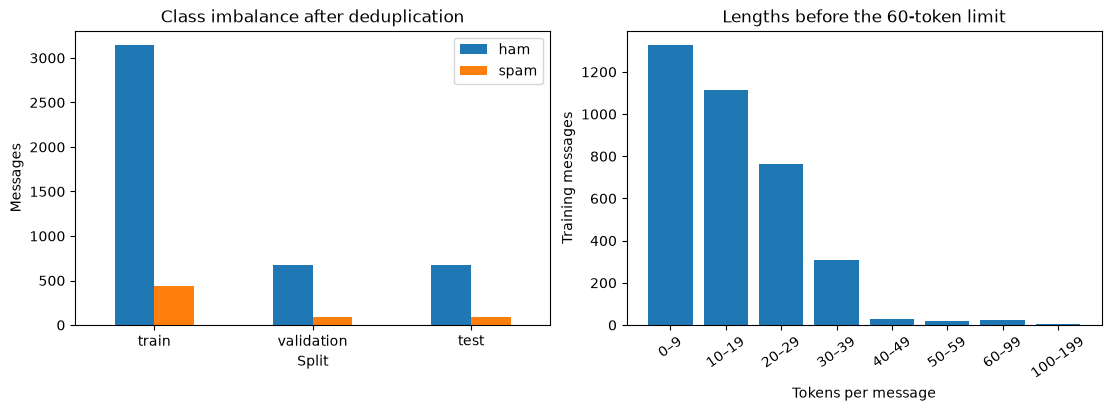

In [5]:
display(pd.DataFrame(metadata["class_counts"]).T.assign(total=pd.Series(metadata["split_counts"])))
print("Training-only neural vocabulary (including PAD/UNK):", metadata["vocabulary_size_including_reserved"])
print("Training messages truncated above 60 tokens:", metadata["train_messages_over_60_tokens"])
data_summary(result)
plt.show()


## 5. Predeclared comparisons

Two non-neural baselines provide context: the training-majority class and
TF-IDF word unigrams/bigrams with multinomial naive Bayes. TF-IDF uses full
normalized messages; recurrent models use the first 60 tokens. Neither learns
features from held-out data.

The four recurrent runs share embedding size 50, hidden size 80 per direction,
batch size 16, five epochs, Adam, and gradient clipping at 2. The first two have
the same architecture and initial weights, isolating learning rate. The next
comparison changes only the dense head, and the last changes directionality.
Different architectures have different parameter counts. There is no pretrained
embedding, class weighting, or decision-threshold search.

Dense hidden layers use ReLU. The final layer returns two logits;
`CrossEntropyLoss` handles the softmax internally. The best checkpoint maximizes
validation **spam F1**, with the earlier epoch retained on ties.

,name,learning_rate,head_sizes,bidirectional
0,LSTM baseline,0.010,[10],False
1,LSTM lower learning rate,0.001,[10],False
2,LSTM deeper head,0.001,"[30, 10]",False
3,BiLSTM deeper head,0.001,"[30, 10]",True


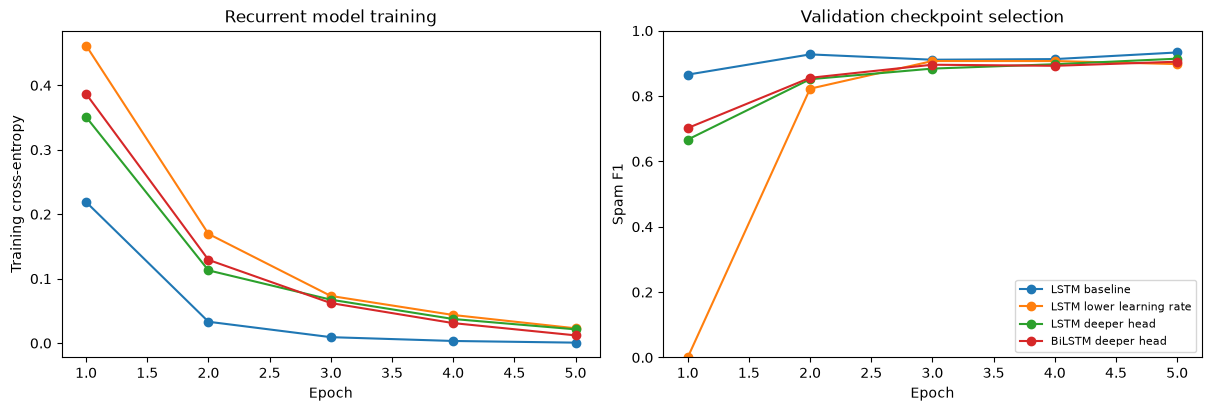

In [6]:
display(pd.DataFrame(metadata["experiments"]))
learning_curves(result)
plt.show()


## 6. Compare held-out detection of spam

- **Accuracy:** fraction of all messages classified correctly.
- **Spam precision:** fraction of spam predictions that really are spam.
- **Spam recall:** fraction of actual spam messages caught.
- **Spam F1:** harmonic mean of spam precision and recall.

Spam is the positive class. Blocking a normal message is a false positive;
letting spam through is a false negative. All models use argmax at prediction;
the test set does not choose a threshold. The selected configuration maximizes
validation spam F1, not test accuracy.

,model,best_epoch,validation_spam_f1,test_accuracy,test_spam_precision,test_spam_recall,test_spam_f1
0,Majority baseline,0,0.0000,0.8779,0.0000,0.0000,0.0000
1,TF-IDF + naive Bayes,0,0.8101,0.9623,1.0000,0.6915,0.8176
2,LSTM baseline,5,0.9333,0.9831,0.9263,0.9362,0.9312
3,LSTM lower learning rate,3,0.9071,0.9792,0.9535,0.8723,0.9111
4,LSTM deeper head,5,0.9143,0.9805,0.9877,0.8511,0.9143
5,BiLSTM deeper head,5,0.9050,0.9753,0.9310,0.8617,0.8950


Selected using validation: LSTM baseline, epoch 5.
Test accuracy: 98.31%; spam F1: 0.931.


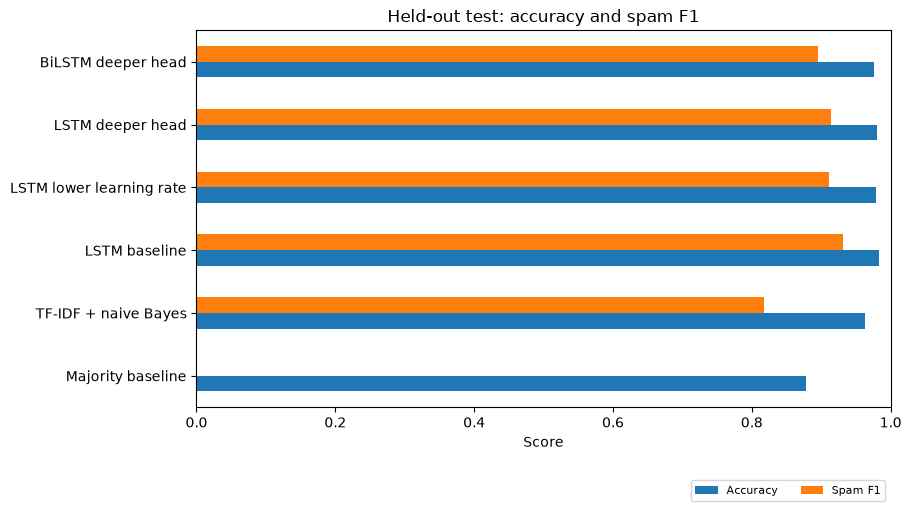

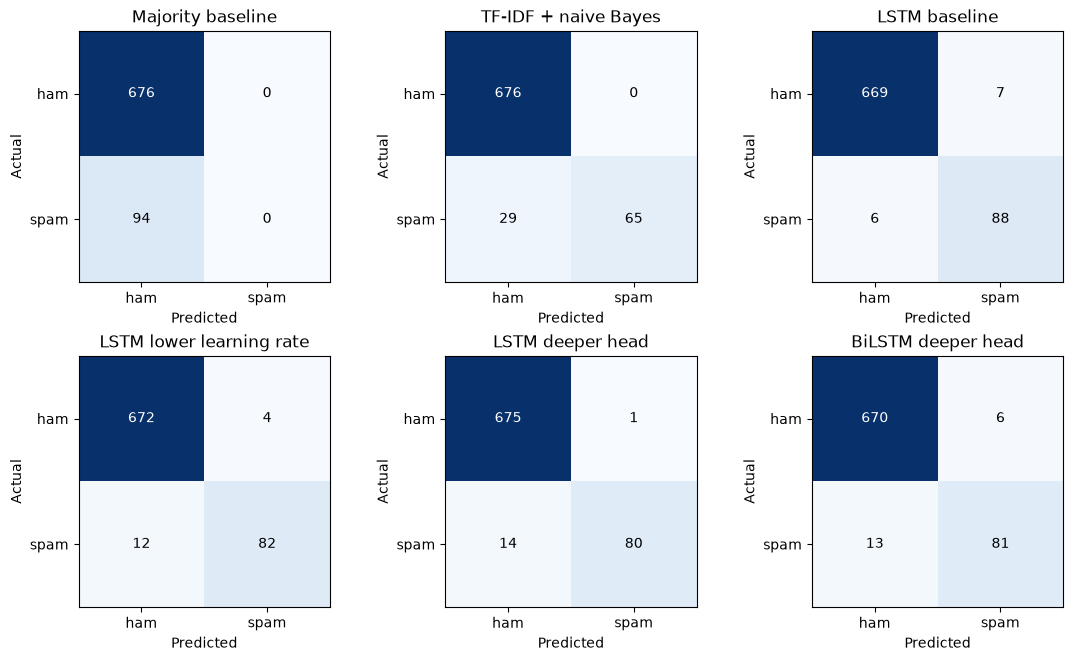

In [7]:
columns = ["model", "best_epoch", "validation_spam_f1", "test_accuracy", "test_spam_precision", "test_spam_recall", "test_spam_f1"]
display(result["metrics"][columns].round(4))
chosen = result["metrics"].loc[result["metrics"].selected_by_validation].iloc[0]
print(f"Selected using validation: {chosen['model']}, epoch {int(chosen['best_epoch'])}.")
print(f"Test accuracy: {chosen['test_accuracy']:.2%}; spam F1: {chosen['test_spam_f1']:.3f}.")
comparison(result)
plt.show()
confusion_matrices(result)
plt.show()


## 7. Interpret the comparisons

Use the measured results, rather than assuming that a larger or bidirectional
model must win. The confusion matrices reveal the tradeoff between missed spam
and blocked normal messages. Timing below includes fitting and validation;
it is measured on this machine and is not a portable performance benchmark.

The parameter column counts trainable PyTorch tensors; non-neural baselines
use zero as a placeholder.

In [8]:
metrics = result["metrics"].set_index("model")
majority = metrics.loc["Majority baseline"]
print(f"Predicting only ham reaches {majority['test_accuracy']:.2%} accuracy, but spam F1 is {majority['test_spam_f1']:.3f}.")
for left, right in [("LSTM baseline", "LSTM lower learning rate"),
                    ("LSTM lower learning rate", "LSTM deeper head"),
                    ("LSTM deeper head", "BiLSTM deeper head")]:
    change = metrics.loc[right, "validation_spam_f1"] - metrics.loc[left, "validation_spam_f1"]
    print(f"{left} -> {right}: validation spam F1 change {change:+.3f}.")

counts = result["confusion"][result["confusion"].model == chosen["model"]]
matrix = counts.pivot(index="actual", columns="predicted", values="count").loc[["ham", "spam"], ["ham", "spam"]]
print(f"Selected model: {matrix.loc['spam', 'spam']} spam caught, {matrix.loc['spam', 'ham']} spam missed, "
      f"{matrix.loc['ham', 'spam']} normal messages blocked.")
display(result["metrics"][["model", "parameters", "training_seconds"]].round(3))


Predicting only ham reaches 87.79% accuracy, but spam F1 is 0.000.
LSTM baseline -> LSTM lower learning rate: validation spam F1 change -0.026.
LSTM lower learning rate -> LSTM deeper head: validation spam F1 change +0.007.
LSTM deeper head -> BiLSTM deeper head: validation spam F1 change -0.009.
Selected model: 88 spam caught, 6 spam missed, 7 normal messages blocked.


,model,parameters,training_seconds
0,Majority baseline,0,0.002
1,TF-IDF + naive Bayes,0,0.077
2,LSTM baseline,405572,7.114
3,LSTM lower learning rate,405572,6.451
4,LSTM deeper head,407502,6.573
5,BiLSTM deeper head,452142,11.627


## Limits and next steps

The checked run selects the ordinary LSTM. BiLSTM does not improve that run.
This is one random split and one seed on an older dataset, so it does not show
that forward-only models are universally better. A lower learning rate may
need a longer schedule. Preprocessing, deduplication, source-version changes,
padding behavior, and a separate test split also prevent direct comparison to
the earlier MATLAB report.

Only 94 spam messages appear in this test split; a handful of errors can move
the metrics appreciably. Near-duplicate templates may still inflate results,
and five epochs is a small training budget. Future work could report repeated
seeds, choose a threshold with validation data for a stated false-positive cost,
and evaluate a separately licensed, more recent corpus. Do not tune those
choices repeatedly against the current test set.

The public outputs contain aggregate results only. The original corpus/readme
remain local, and invented examples are clearly marked. The
[source notices](../THIRD_PARTY_NOTICES.md) distinguish the module's MIT code,
separately installed libraries, UCI's dataset license, and the earlier MathWorks
example. Attribution does not imply endorsement or replace other rights.
